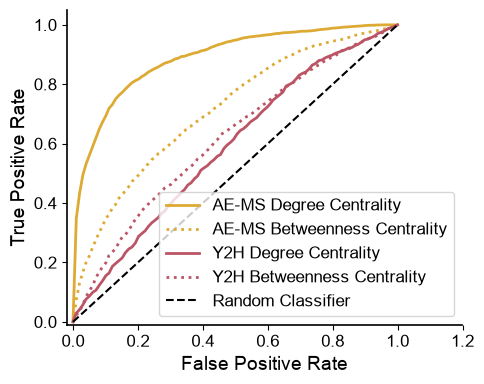

In [2]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.metrics import auc

# Set global plot aesthetics
mpl.rcParams['font.family'] = 'Arial'  # Use 'sans-serif' if Arial is unavailable
mpl.rcParams['font.size'] = 12
mpl.rcParams['axes.linewidth'] = 1.2  # Linewidth for x and y axis spines

# List of CSV files and corresponding labels/styles
# Update filenames to match your saved CSVs (e.g., 'roc_ae_ms_degree.csv')
models = [
    {
        'file': 'roc_MS_degree_50models.csv',  # AE-MS Degree Centrality
        'label': 'AE-MS Degree Centrality',
        'color': '#DDAA33',
        'linestyle': '-',
        'marker': None
    },
    {
        'file': 'roc_MS_betweenness_50models.csv',  # AE-MS Betweenness Centrality
        'label': 'AE-MS Betweenness Centrality',
        'color': '#DDAA33',
        'linestyle': ':',
        'marker': None
    },
    {
        'file': 'roc_Y2H_degree_50models.csv',  # Y2H Degree Centrality
        'label': 'Y2H Degree Centrality',
        'color': '#BB5566',
        'linestyle': '-',
        'marker': None
    },
    {
        'file': 'roc_Y2H_betweenness_50models.csv',  # Y2H Betweenness Centrality
        'label': 'Y2H Betweenness Centrality',
        'color': '#BB5566',
        'linestyle': ':',
        'marker': None
    }
]

# Create figure
fig, ax = plt.subplots(figsize=(5, 4))

for model in models:
    df = pd.read_csv(model['file'])
    fpr = df['False_Positive_Rate'].values
    tpr = df['Mean_True_Positive_Rate'].values
    # Optional: roc_auc = auc(fpr, tpr)  # If you want to add AUC to label
    # label = f"{model['label']} (AUC = {roc_auc:.3f})"
    label = model['label']  # No AUC as in the image
    
    ax.plot(fpr, tpr,
            color=model['color'],
            linestyle=model['linestyle'],
            marker=model['marker'],
            label=label,
            linewidth=2,  # Adjust if needed
            markersize=4)   # Small markers to match dots


# add diagonal random-classifier line
ax.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Classifier')

# Set labels and limits (no title, no grid, no random line as in the image)
ax.set_xlabel('False Positive Rate', fontsize=14)
ax.set_ylabel('True Positive Rate', fontsize=14)
ax.set_xlim([-0.02, 1.2])
ax.set_ylim([-0.01, 1.05])

# Hide top and right axes (only show X and Y)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legend inside the plot, adjust position to match image (lower right)
ax.legend(loc='lower right', fontsize=12, frameon=True)

# Tight layout and show
plt.tight_layout()
plt.savefig(f"4-a.svg")
plt.show()